# Toronto Bike Share — E-bike vs Conventional Cycling, June 2024

**Outputs:** (1) full-month two-colour route overlay, (2) daily overlay frames, (3) animated GIF, (4) daily counts and e-bike share. Uses the existing June trip Parquet and 163,026 GraphHopper OD routes in SQLite; no further routing required.

**Interpretation:** These are modelled routes, not observed trajectories. Conventional bikes are **magenta**; electric bikes are **cyan**. Routes are weighted by OD trip frequency. The daily maps use consistent spatial limits and weighting. Existing same-station, missing-coordinate and nonpositive-duration exclusions still apply. A 2026 OSM extract and provisional station coordinates were used for routing. The electric and conventional groups use the **same routing profile**.


In [1]:
from pathlib import Path
import sqlite3, json
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import shape
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from PIL import Image
from IPython.display import display

PROJECT = Path('/scratch/project_2010417/paper3/toronto-bike-exposure')
DATA = PROJECT / 'data/processed'
OUT = PROJECT / 'outputs/maps/bike_type'
FRAMES = OUT / 'frames'
FRAMES.mkdir(parents=True, exist_ok=True)
TRIPS_FILE = DATA / 'bikeshare_june_2024_validated.parquet'
ROUTES_FILE = DATA / 'full_june_routes.sqlite'
for f in (TRIPS_FILE, ROUTES_FILE):
    if not f.exists():
        raise FileNotFoundError(f)
COLORS = {'Conventional':'#ff4fd8', 'Electric':'#00e5ff'}
BG = '#04070d'
print('Project:', PROJECT)


Project: /scratch/project_2010417/paper3/toronto-bike-exposure


## 1. Classify bicycles and retain successfully routed trips

In [2]:
trips = pd.read_parquet(TRIPS_FILE)
print('Original Bike_Model values:')
display(trips['Bike_Model'].value_counts(dropna=False).to_frame('trips'))

def classify_bike(x):
    if pd.isna(x): return 'Unknown'
    x = str(x).strip().upper()
    if x.startswith('EFIT'): return 'Electric'
    if x == 'ICONIC': return 'Conventional'
    return 'Unknown'

trips['bike_type'] = trips['Bike_Model'].map(classify_bike)
trips['date'] = pd.to_datetime(trips['Start_Time'], errors='coerce').dt.normalize()
trips['Trip_Duration'] = pd.to_numeric(trips['Trip_Duration'],errors='coerce')
for c in ('Start_Station_Id','End_Station_Id'):
    trips[c] = trips[c].astype('string').str.strip().str.replace(r'\.0+$','',regex=True)

eligible = trips.loc[
    trips.bike_type.isin(['Electric','Conventional']) &
    trips.date.between(pd.Timestamp('2024-06-01'),pd.Timestamp('2024-06-30')) &
    trips['Start_Station_Id'].notna() & trips['End_Station_Id'].notna() &
    trips['Start_Station_Id'].ne(trips['End_Station_Id']).fillna(False) &
    trips['Trip_Duration'].gt(0)
].copy()
print('Bike types (all June records):')
display(trips.bike_type.value_counts(dropna=False).to_frame('trips'))
print('Potentially eligible before route match:',f'{len(eligible):,}')


Original Bike_Model values:


,trips
Bike_Model,
ICONIC,633526
EFIT G5,87426
EFIT,45916


Bike types (all June records):


,trips
bike_type,
Conventional,633526
Electric,133342


Potentially eligible before route match: 741,514


## 2. Load GraphHopper geometries and count daily/monthly OD use

In [3]:
with sqlite3.connect(ROUTES_FILE) as conn:
    route_sql = pd.read_sql_query('''SELECT start_id, end_id, geometry_json FROM routes
        WHERE geometry_json IS NOT NULL''',conn)

route_sql['start_id']=route_sql['start_id'].astype('string')
route_sql['end_id']=route_sql['end_id'].astype('string')
route_keys = pd.MultiIndex.from_frame(route_sql[['start_id','end_id']])
trip_keys = pd.MultiIndex.from_frame(eligible[['Start_Station_Id','End_Station_Id']])
eligible = eligible.loc[trip_keys.isin(route_keys)].copy()

monthly = (eligible.groupby(['Start_Station_Id','End_Station_Id','bike_type'],observed=True)
           .size().rename('n').reset_index())
daily = (eligible.groupby(['date','Start_Station_Id','End_Station_Id','bike_type'],observed=True)
         .size().rename('n').reset_index())

# Decode and reproject each unique route once.
route_geo = gpd.GeoDataFrame(
    route_sql.drop(columns='geometry_json'),
    geometry=[shape(json.loads(s)) for s in route_sql.geometry_json],
    crs='EPSG:4326'
).to_crs('EPSG:26917')
route_geo = route_geo.loc[route_geo.geometry.geom_type.eq('LineString')].copy()
# Keep a plain Pandas table of geometry objects; for plotting, segment arrays are cached once.
route_geo['segment'] = [np.asarray(g.coords, dtype='float64') for g in route_geo.geometry]
route_parts = route_geo[['start_id','end_id','segment']].copy()

# Join only the arrays; avoid decoding or projecting geometries for every day.
monthly = monthly.merge(route_parts,left_on=['Start_Station_Id','End_Station_Id'],
                        right_on=['start_id','end_id'],how='inner',validate='many_to_one')
daily = daily.merge(route_parts,left_on=['Start_Station_Id','End_Station_Id'],
                    right_on=['start_id','end_id'],how='inner',validate='many_to_one')
assert int(monthly['n'].sum()) == int(daily['n'].sum())
print('Successfully routed trips by type:')
display(eligible.bike_type.value_counts().to_frame('trips'))
print('Monthly plot OD/type rows:',f'{len(monthly):,}')
print('Daily plot OD/type rows:',f'{len(daily):,}')
print('Trips represented by rendered routes:', f'{monthly.n.sum():,}')


Successfully routed trips by type:


,trips
bike_type,
Conventional,608661
Electric,129254


Monthly plot OD/type rows: 214,453
Daily plot OD/type rows: 602,790
Trips represented by rendered routes: 737,915


## 3. Shared styling and geometry limits

In [4]:
xmin,ymin,xmax,ymax = route_geo.total_bounds
pad_x, pad_y = (xmax-xmin)*.025, (ymax-ymin)*.025
BOUNDS = (xmin-pad_x, xmax+pad_x, ymin-pad_y, ymax+pad_y)
DAILY_MAX = max(1,int(daily.n.max()))
MONTHLY_MAX = max(1,int(monthly.n.max()))

# Per-OD line widths use the same normalisation across both bike types for each time scale.
def glow(ax, subset, color, normalizer):
    if subset.empty: return
    segments=subset['segment'].tolist()
    counts=subset['n'].to_numpy(dtype=float)
    widths=0.22+1.35*np.log1p(counts)/np.log1p(normalizer)
    for factor,opacity in [(6,0.014),(2.8,0.055),(.85,.26)]:
        ax.add_collection(LineCollection(segments, colors=color,
                         linewidths=widths*factor,alpha=opacity,
                         capstyle='round',rasterized=True))

def style_map(ax):
    ax.set_facecolor(BG)
    ax.set_xlim(BOUNDS[0],BOUNDS[1]); ax.set_ylim(BOUNDS[2],BOUNDS[3])
    ax.set_aspect('equal'); ax.axis('off')

def legend(ax):
    handles=[Line2D([0],[0],color=COLORS[t],lw=3,label=t+' bikes')
             for t in ('Electric','Conventional')]
    lg=ax.legend(handles=handles,loc='lower right',facecolor='#101827',
                 edgecolor='#445364',labelcolor='white',framealpha=.95,fontsize=10)
    return lg


## 4. Full-month overlay (both bicycle types on one map)

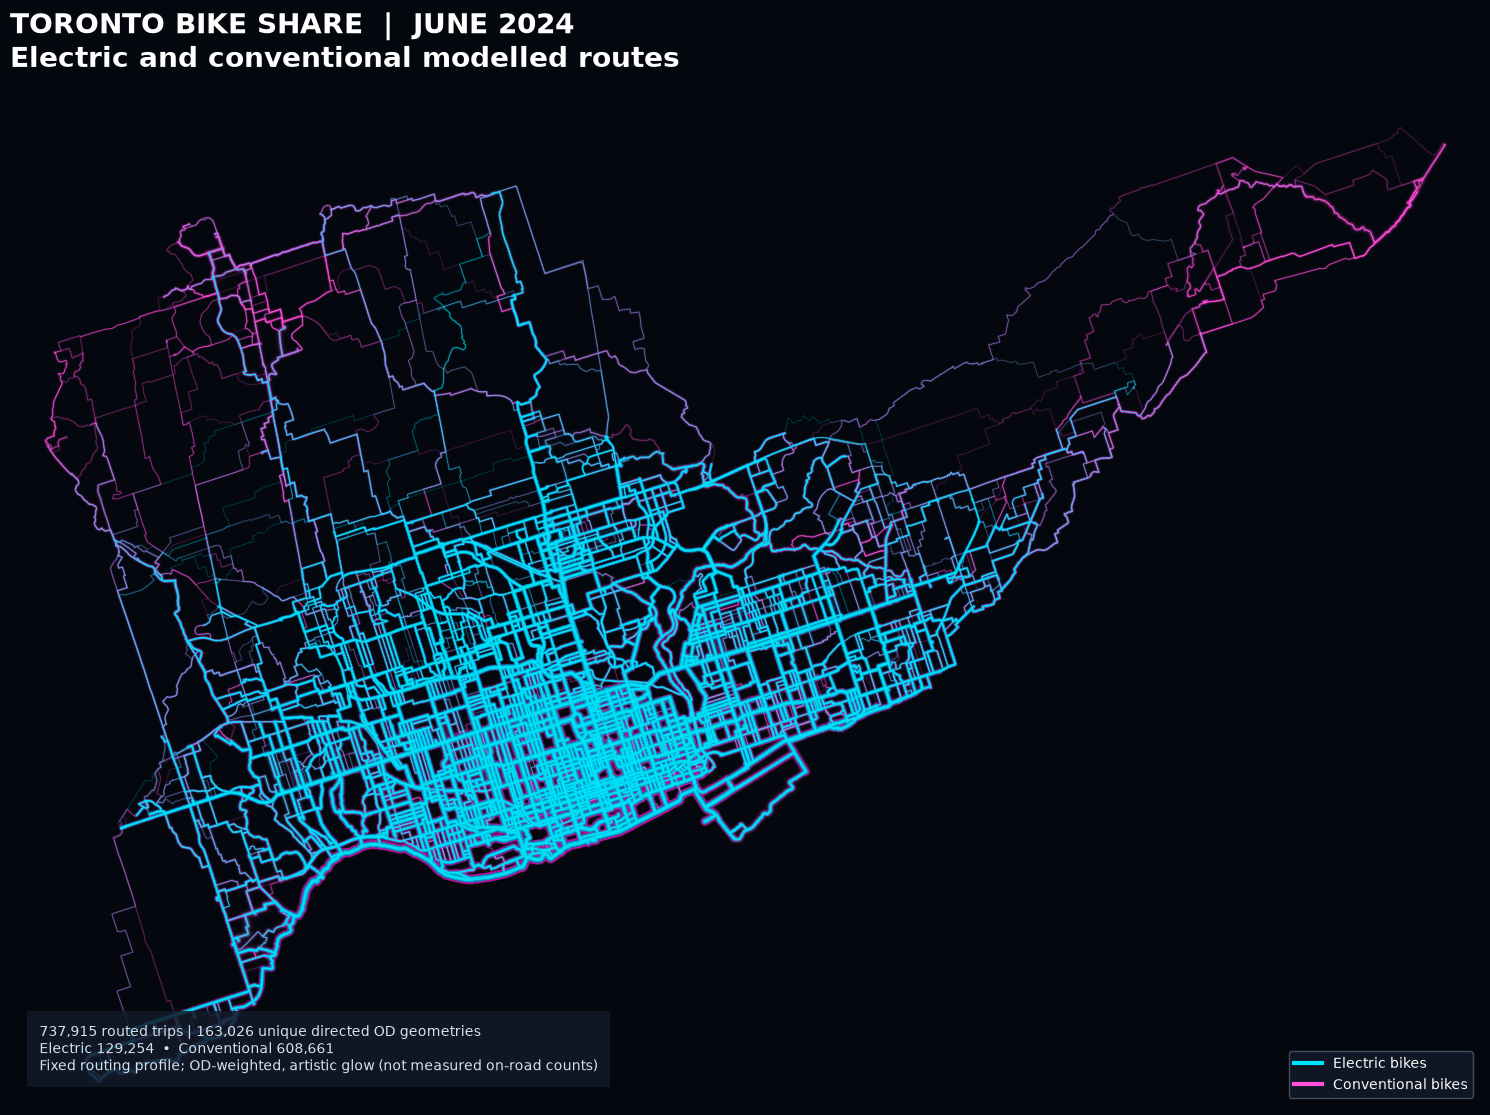

Saved /scratch/project_2010417/paper3/toronto-bike-exposure/outputs/maps/bike_type/june_2024_electric_conventional_overlay.png


In [5]:
fig,ax=plt.subplots(figsize=(15,12),facecolor=BG)
style_map(ax)
# Draw larger group first, then electric for visibility.
for t in ('Conventional','Electric'):
    glow(ax,monthly.loc[monthly.bike_type.eq(t)],COLORS[t],MONTHLY_MAX)
legend(ax)
ax.set_title('TORONTO BIKE SHARE  |  JUNE 2024\nElectric and conventional modelled routes',
             fontsize=20,color='white',loc='left',pad=16,weight='bold')
counts=eligible.bike_type.value_counts()
info=(f"{len(eligible):,} routed trips | {len(route_geo):,} unique directed OD geometries\n"
      f"Electric {counts.get('Electric',0):,}  •  Conventional {counts.get('Conventional',0):,}\n"
      'Fixed routing profile; OD-weighted, artistic glow (not measured on-road counts)')
ax.text(.02,.03,info,transform=ax.transAxes,color='#d3e3ed',fontsize=10,va='bottom',
        bbox={'facecolor':'#111b29','edgecolor':'none','alpha':.85,'pad':9})
fig.tight_layout()
path=OUT/'june_2024_electric_conventional_overlay.png'
fig.savefig(path,dpi=220,facecolor=BG,bbox_inches='tight')
plt.show();print('Saved',path)


## 5. Daily frames — identical scales across all 30 days

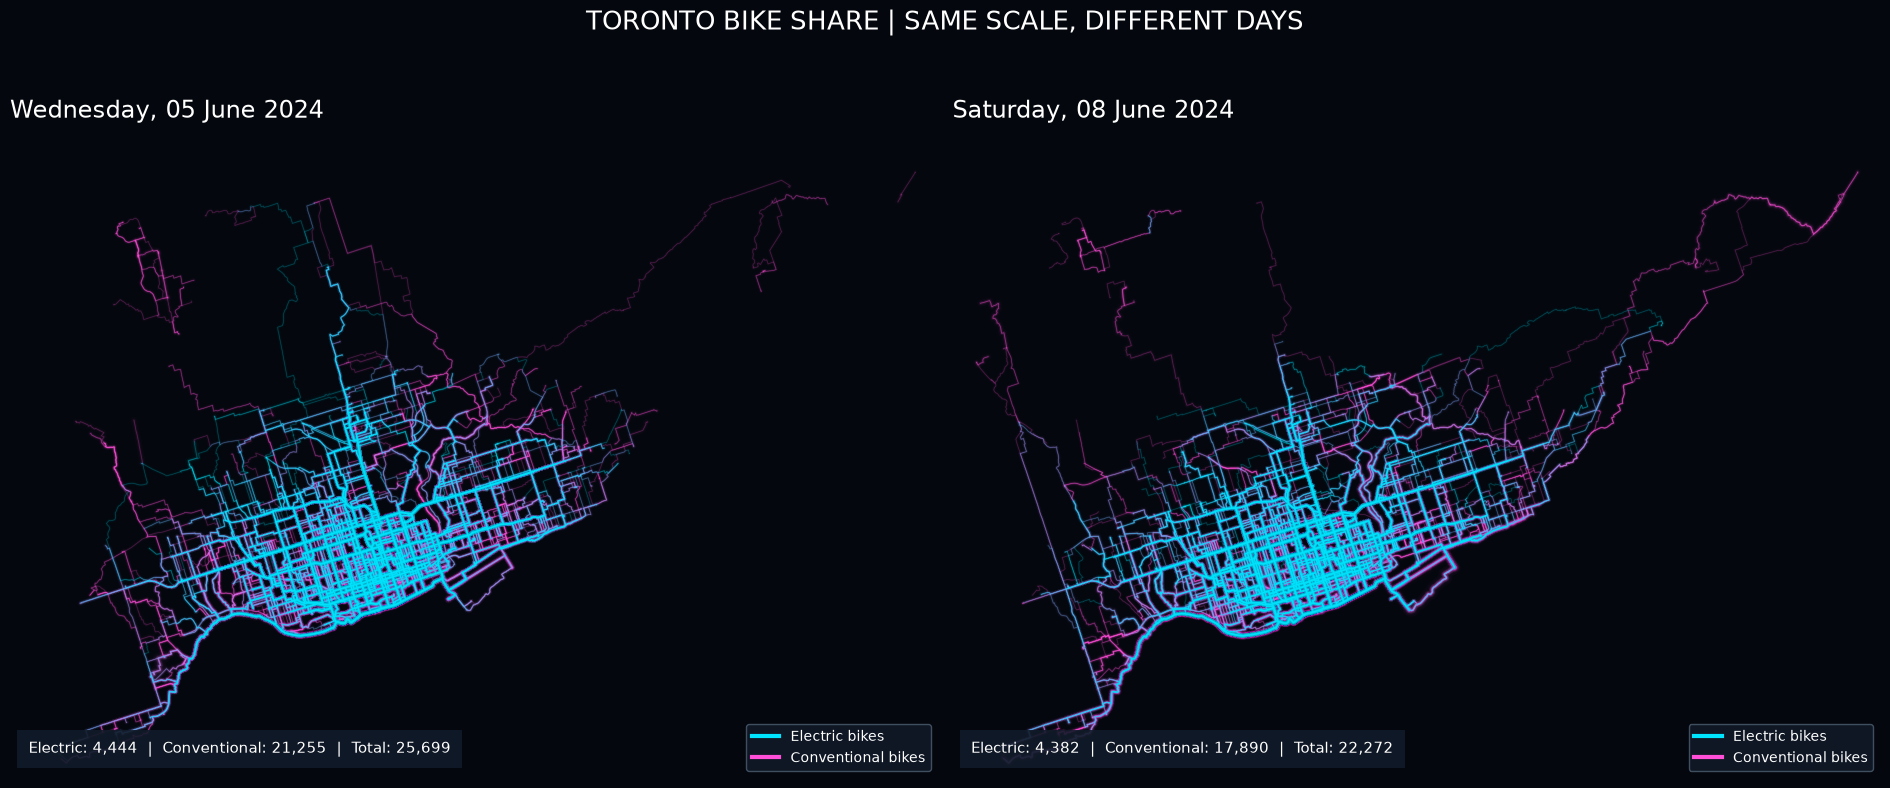

Saved /scratch/project_2010417/paper3/toronto-bike-exposure/outputs/maps/bike_type/daily_comparison_2024_06_05_vs_08.png


In [6]:
def render_day(day, ax):
    day=pd.Timestamp(day)
    subset=daily.loc[daily.date.eq(day)]
    style_map(ax)
    for t in ('Conventional','Electric'):
        glow(ax,subset.loc[subset.bike_type.eq(t)],COLORS[t],DAILY_MAX)
    legend(ax)
    e=int(subset.loc[subset.bike_type.eq('Electric'),'n'].sum())
    c=int(subset.loc[subset.bike_type.eq('Conventional'),'n'].sum())
    ax.set_title(day.strftime('%A, %d %B %Y'),color='white',fontsize=17,loc='left',pad=10)
    ax.text(.02,.04,f'Electric: {e:,}  |  Conventional: {c:,}  |  Total: {e+c:,}',
            transform=ax.transAxes,color='white',fontsize=11,
            bbox={'facecolor':'#111b29','edgecolor':'none','alpha':.9,'pad':8})

fig,axs=plt.subplots(1,2,figsize=(19,9),facecolor=BG)
render_day('2024-06-05',axs[0]);render_day('2024-06-08',axs[1])
fig.suptitle('TORONTO BIKE SHARE | SAME SCALE, DIFFERENT DAYS',color='white',fontsize=19)
fig.tight_layout()
path=OUT/'daily_comparison_2024_06_05_vs_08.png'
fig.savefig(path,dpi=160,facecolor=BG,bbox_inches='tight')
plt.show(); print('Saved',path)


## 6. Generate 30 daily maps and an animated GIF

The PNG images have the same canvas size, spatial bounds and colour/width rules; this is essential for meaningful visual comparison. Rendering all 30 frames may use significant notebook memory; each figure is closed after saving.

In [7]:
for day in pd.date_range('2024-06-01','2024-06-30'):
    fig,ax=plt.subplots(figsize=(12,10),facecolor=BG)
    render_day(day,ax)
    ax.text(.02,.97,'TORONTO BIKE SHARE  •  JUNE 2024',transform=ax.transAxes,
            color='#b9c8d6',fontsize=11,va='top')
    frame=FRAMES/f"day_{day:%Y_%m_%d}.png"
    # No bbox_inches='tight' to preserve identical frame pixel dimensions.
    fig.savefig(frame,dpi=125,facecolor=BG)
    plt.close(fig)
print('Saved daily frames:',len(list(FRAMES.glob('day_2024_06_*.png'))))


Saved daily frames: 30


In [8]:
frame_files=sorted(FRAMES.glob('day_2024_06_*.png'))
assert len(frame_files)==30, f'Expected 30 frames, found {len(frame_files)}'
gif_path=OUT/'june_2024_electric_conventional_daily.gif'
first=Image.open(frame_files[0]).convert('RGB').quantize(colors=256)
append=[]
for file in frame_files[1:]:
    with Image.open(file) as im:
        append.append(im.convert('RGB').quantize(colors=256))
first.save(gif_path,save_all=True,append_images=append,duration=650,loop=0,optimize=False)
first.close()
for im in append: im.close()
print('Saved',gif_path)


Saved /scratch/project_2010417/paper3/toronto-bike-exposure/outputs/maps/bike_type/june_2024_electric_conventional_daily.gif


## 7. Daily trip counts and e-bike share

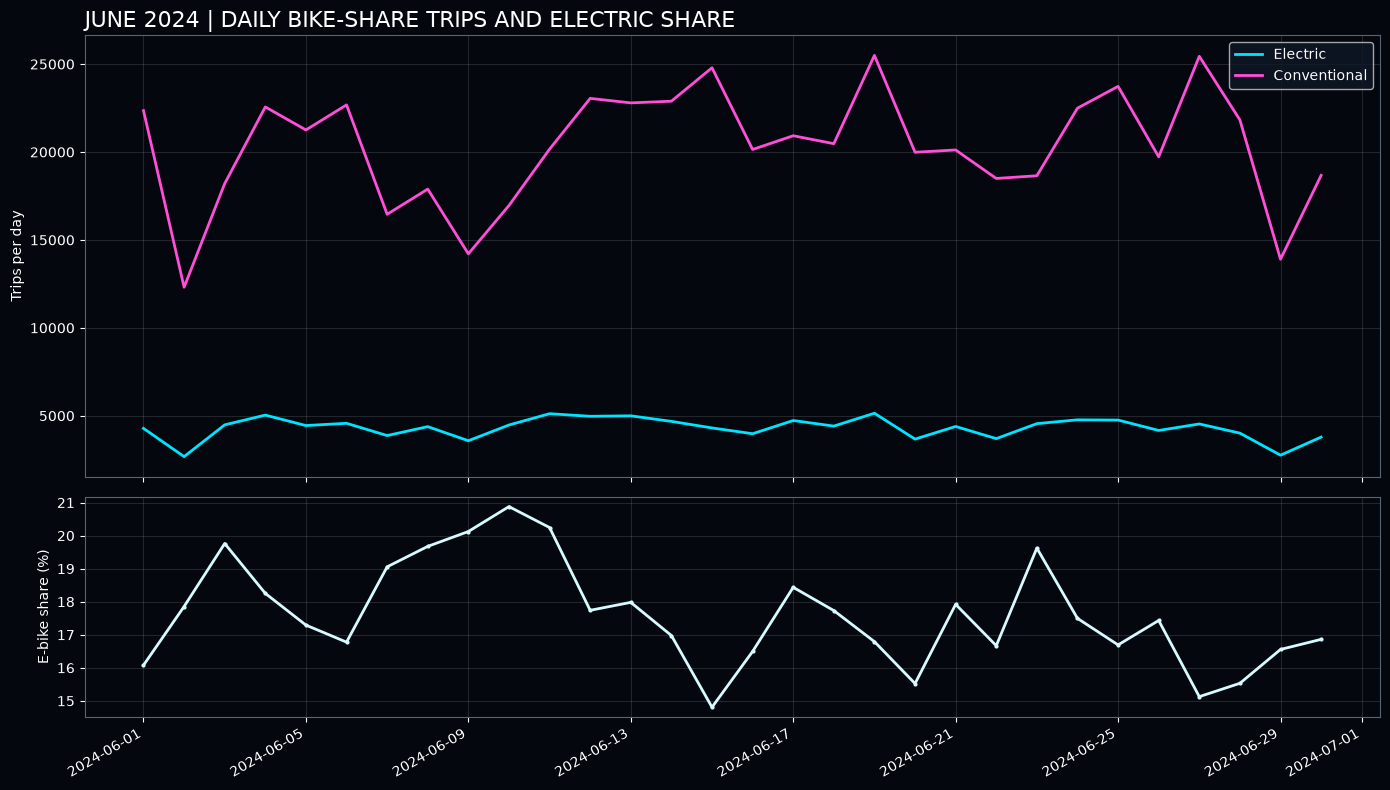

Saved /scratch/project_2010417/paper3/toronto-bike-exposure/outputs/maps/bike_type/daily_trip_counts_and_electric_share.png


In [9]:
counts=(eligible.groupby(['date','bike_type']).size().unstack(fill_value=0)
        .reindex(pd.date_range('2024-06-01','2024-06-30'),fill_value=0))
counts['Electric share (%)']=100*counts.get('Electric',0)/counts[['Electric','Conventional']].sum(axis=1).replace(0,np.nan)
fig,axs=plt.subplots(2,1,figsize=(14,8),facecolor=BG,sharex=True,
                     gridspec_kw={'height_ratios':[2,1]})
for ax in axs:
    ax.set_facecolor(BG)
    ax.tick_params(colors='white')
    for spine in ax.spines.values():spine.set_color('#586575')
    ax.grid(alpha=.12,color='white')
for t in ('Electric','Conventional'):
    axs[0].plot(counts.index,counts[t],color=COLORS[t],lw=2,label=t)
axs[0].set_ylabel('Trips per day',color='white');axs[0].legend(labelcolor='white',facecolor='#101827')
axs[1].plot(counts.index,counts['Electric share (%)'],color='#d7faff',lw=2,marker='.',ms=4)
axs[1].set_ylabel('E-bike share (%)',color='white')
axs[0].set_title('JUNE 2024 | DAILY BIKE-SHARE TRIPS AND ELECTRIC SHARE',
                 loc='left',color='white',fontsize=16)
fig.autofmt_xdate();fig.tight_layout()
path=OUT/'daily_trip_counts_and_electric_share.png'
fig.savefig(path,dpi=220,facecolor=BG,bbox_inches='tight')
plt.show();print('Saved',path)


## Interpretation and limitations

- **E-bike colour is based on `Bike_Model`** (`EFIT*` as electric; `ICONIC` as conventional). Confirm other model names in the first table.
- **Daily frames share one visual scale**, but brighter corridors are still stylistic overlap of modelled OD routes, not independently measured cyclist counts on road segments.
- The full routing dataset excludes some station-missing, same-station and nonpositive-duration trips. The counts shown here describe **successfully routed trips in the two known bike-model categories**.
- More conventional-bike trips may obscure electric-bike lines in a blended overlay. Use the daily count chart and electric share, not hue dominance alone, for comparisons.
- Trip IDs are not mapped to recorded GPS tracks. Both bike types follow the same GraphHopper routing profile. For bike-specific route choice and exposure, further modelling would be needed.
- To reproduce the 2024 street network historically, we would also need a historical OSM extract and closer-to-2024 station coordinates.
